# Project 2: Players, Clubs and Islands in 30 Years of European Football Transfers

**Joao De Oliveira**

## Question
European football has two distinct kinds of nodes: **players** and **clubs**. A player is tied to every club he has played for, so all ties run between the two groups, never within them. What can we infer about each group, the clubs and the players, from this two mode network?

## Data
[ewenme/transfers](https://github.com/ewenme/transfers) on GitHub: every transfer recorded on [Transfermarkt](https://www.transfermarkt.com/) for the clubs of 9 European leagues (Premier League, Championship, La Liga, Serie A, Bundesliga, Ligue 1, Liga Portugal, Eredivisie and the Russian Premier League) from the 1992/93 to 2022/23 seasons, which is about 177,000 transfer records. Each record names the player, his age and position, the club, the other club involved, the fee and whether it was a loan.

## Approach
1. Build the two-mode network: players × clubs, with an edge when a player joined or left a club.
2. Project it onto the clubs: two clubs are tied by the number of players they have shared.
3. Reduce the network with the island method (Tsvetovat & Kouznetsov, Social Network Analysis for Startups, Chapter 4): raise a "water level" on the edge weights and keep only ties above it, so that the tightly linked groups of clubs appear as islands.
4. Apply the same method to the players' side to find groups of players whose careers followed the same path.
5. Interpret both groups and check that the results are not driven by data problems.

## 0. Setup

In [ ]:
import os, re
import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
from scipy import sparse, stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

pd.set_option("display.max_colwidth", 120)
print("networkx", nx.__version__)

networkx 3.6.1


## 1. Load the data from GitHub
The repository has one CSV per league. I download each file once and cache it locally, so rerunning the notebook doesn't download them again.

In [ ]:
BASE = "https://raw.githubusercontent.com/ewenme/transfers/master/data/"
LEAGUES = ["premier-league", "championship", "primera-division", "serie-a", "1-bundesliga",
           "ligue-1", "liga-nos", "eredivisie", "premier-liga"]
CACHE = "transfers_cache"
os.makedirs(CACHE, exist_ok=True)

frames = []
for lg in LEAGUES:
    path = os.path.join(CACHE, f"{lg}.csv")
    if not os.path.exists(path):
        pd.read_csv(BASE + f"{lg}.csv").to_csv(path, index=False)
    frames.append(pd.read_csv(path))
raw = pd.concat(frames, ignore_index=True)

print(f"Transfer records: {len(raw):,} | seasons {raw.year.min()}-{raw.year.max()}")
raw.groupby(["country", "league_name"]).size().rename("records").to_frame()

Transfer records: 177,412 | seasons 1992-2022


records
country     league_name              
England     Championship        24241
            Premier League      23675
France      Ligue 1             17580
Germany     1 Bundesliga        14158
Italy       Serie A             28433
Netherlands Eredivisie          15264
Portugal    Liga Nos            21734
Russia      Premier Liga        14947
Spain       Primera Division    17380

## 2. Clean the data
Three problems need fixing before building the network.

**1. Players have no ID, only a name.** Common names like "João Pedro" or "Fernando" belong to many different people. I identify a player by **name + estimated birth year** (transfer year minus age). Records of the same name are treated as one person when their birth years are within one year of each other.

**2. Some clubs appear under two names** after a rename or refounding (for example "FC Internazionale" → "Inter Milan", "Terek Grozny" → "Akhmat Grozny"). If I left them separate, a club would look strongly tied to itself. I merged only renames of the same club, checked by hand: same league, years that don't overlap, and many shared players.

**3. Positions** are recorded at different levels of detail, so I group them into Goalkeeper, Defender, Midfielder and Forward, as in Project 1.

In [ ]:
d = raw.dropna(subset=["player_name", "club_name", "age"]).copy()

# 1 player identity includes name + estimated birth year (gap > 1 year = a different person)
d["birth_est"] = (d["year"] - d["age"]).astype(int)

def split_by_birth(group):
    years = np.sort(group["birth_est"].unique())
    person, ids, prev = 0, {}, None
    for y in years:
        if prev is not None and y - prev > 1:
            person += 1
        ids[y], prev = person, y
    return group["birth_est"].map(ids)

d["person"] = d.groupby("player_name", group_keys=False)[["birth_est"]].apply(split_by_birth)
d["player"] = d["player_name"] + " #" + d["person"].astype(str)

n_people = d.groupby("player_name")["person"].nunique()
AMBIGUOUS = set(n_people[n_people > 1].index) | {n for n in d["player_name"].unique() if len(n.split()) == 1}
d["ambiguous"] = d["player_name"].isin(AMBIGUOUS)

# 2 club renames (same club, different name over time)
RENAMES = {
    "FC Internazionale": "Inter Milan", "Milan AC": "AC Milan",
    "AC Parma": "Parma", "Parma FC": "Parma", "Parma Calcio 1913": "Parma",
    "AC Fiorentina": "ACF Fiorentina", "Torino Calcio": "Torino FC", "SPAL 2013": "SPAL",
    "FC Empoli": "Empoli FC", "US Salernitana": "US Salernitana 1919",
    "Dinamo Moscow": "Dynamo Moscow", "Rostselmash Rostov": "FK Rostov", "PFK Tambov": "FK Tambov",
    "Торпедо-Лужники Москва": "Torpedo Moscow", "Torpedo-ZiL Moscow": "FC Moscow",
    "Torpedo-Metallurg Moscow": "FC Moscow", "Terek Grozny": "Akhmat Grozny",
    "Saturn REN-TV Ramenskoe": "Saturn Ramenskoe", "Spartak Vladikavkaz": "Alania Vladikavkaz",
    "Spartak-Alania Vladikavkaz": "Alania Vladikavkaz", "FC Pari Nizhniy Novgorod": "FC Nizhniy Novgorod",
    "Uralmash Ekaterinburg": "Ural Yekaterinburg", "Dinamo-Gazovik Tyumen": "FK Tyumen",
    "Belenenses SAD": "CF Os Belenenses", "Association Troyes Aube Champagne": "ESTAC Troyes",
    "FC Zwolle": "PEC Zwolle", "Cambuur-Leeuwarden bvo": "SC Cambuur-Leeuwarden",
    "SC Cambuur Leeuwarden": "SC Cambuur-Leeuwarden",
}
d["club"] = d["club_name"].replace(RENAMES)

# 3 position groups
POS = {"Goalkeeper": "Goalkeeper",
       "Centre-Back": "Defender", "Left-Back": "Defender", "Right-Back": "Defender", "Sweeper": "Defender",
       "defence": "Defender", "Defence": "Defender",
       "Central Midfield": "Midfielder", "Defensive Midfield": "Midfielder", "Attacking Midfield": "Midfielder",
       "Right Midfield": "Midfielder", "Left Midfield": "Midfielder", "midfield": "Midfielder",
       "Centre-Forward": "Forward", "Right Winger": "Forward", "Left Winger": "Forward",
       "Second Striker": "Forward", "attack": "Forward"}
d["pos_group"] = d["position"].map(POS)
d["loan"] = d["fee"].str.contains("loan", case=False, na=False)

print(f"Distinct names: {d.player_name.nunique():,} -> distinct players after the birth-year split: {d.player.nunique():,}")
print(f"Players with an ambiguous name: {d.drop_duplicates('player').ambiguous.mean():.1%}")
print(f"Club names: {d.club_name.nunique()} -> clubs after merging renames: {d.club.nunique()}")

Distinct names: 36,957 -> distinct players after the birth-year split: 38,135
Players with an ambiguous name: 8.5%
Club names: 413 -> clubs after merging renames: 386


## 3. Build the two-mode network
Each node is either a **club** (one of the 9 leagues' clubs) or a **player**. A player is tied to a club if he joined or left it at least once. I keep only the clubs in the 9 leagues (`club_name`), not the "other club" of each transfer, whose names are not standardized.

Clubs: 386 | Players: 38,135 | Player-club ties: 75,610
Bipartite: True | ties within a group: 0 by construction
Density: 0.0051 (share of all possible player-club pairs that occur)


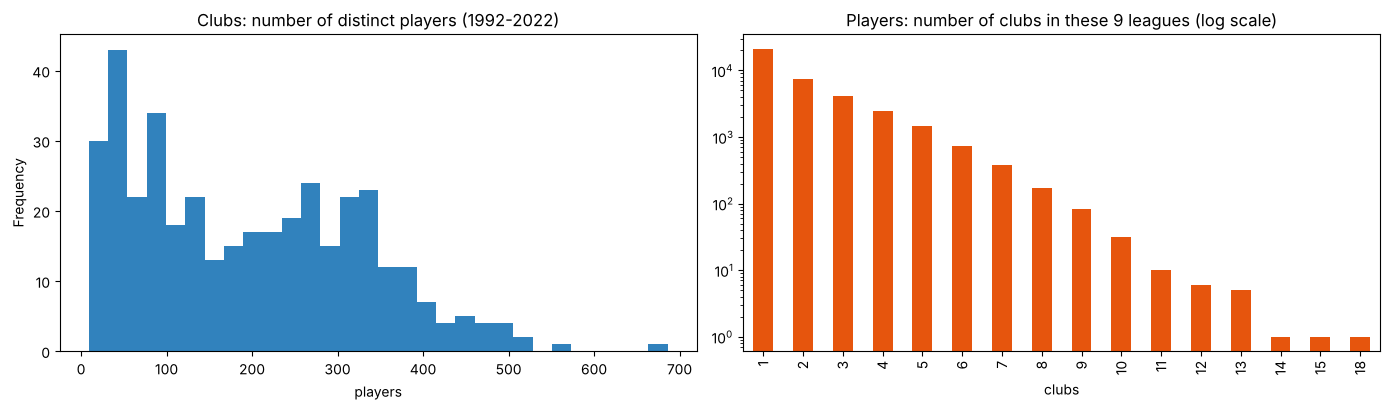

In [ ]:
ties = d[["player", "club"]].drop_duplicates()
COUNTRY = d.groupby("club")["country"].agg(lambda s: s.mode()[0])
B = nx.Graph()
B.add_nodes_from(ties["club"].unique(), bipartite="club")
B.add_nodes_from(ties["player"].unique(), bipartite="player")
B.add_edges_from(ties.itertuples(index=False))
clubs = set(ties["club"]); players = set(ties["player"])

print(f"Clubs: {len(clubs)} | Players: {len(players):,} | Player-club ties: {B.number_of_edges():,}")
print(f"Bipartite: {bipartite.is_bipartite(B)} | ties within a group: 0 by construction")
print(f"Density: {bipartite.density(B, clubs):.4f} (share of all possible player-club pairs that occur)")

club_deg = ties.groupby("club").size()
player_deg = ties.groupby("player").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
club_deg.plot.hist(bins=30, ax=axes[0], color="#3182bd")
axes[0].set_title("Clubs: number of distinct players (1992-2022)"); axes[0].set_xlabel("players")
player_deg.value_counts().sort_index().plot.bar(ax=axes[1], color="#e6550d", logy=True)
axes[1].set_title("Players: number of clubs in these 9 leagues (log scale)"); axes[1].set_xlabel("clubs")
plt.tight_layout(); plt.show()

## 4. Project onto the clubs
In the club projection, two clubs are tied if at least one player played for both, and the **weight is the number of players they shared** over the 30 years.

In [ ]:
C = bipartite.weighted_projected_graph(B, clubs)
w = pd.Series([e["weight"] for *_, e in C.edges(data=True)])

print(f"Club projection: {C.number_of_nodes()} clubs, {C.number_of_edges():,} ties, density {nx.density(C):.2f}")
print(f"Shared players per tie: median {w.median():.0f}, 90th percentile {w.quantile(.9):.0f}, max {w.max():.0f}")
print(f"Connected components: {nx.number_connected_components(C)}")

Club projection: 386 clubs, 19,814 ties, density 0.27
Shared players per tie: median 2, 90th percentile 11, max 62
Connected components: 1


The club projection is one connected "hairball": 386 clubs with almost 20,000 ties, and every club is linked to the rest of Europe through at least one player. Most ties are weak (half of them rest on one or two players). To see real structure, the network has to be reduced.

## 5. Reducing the network with the island method
The island method (Chapter 4) treats edge weights like terrain: imagine the network as a landscape and raise the water level step by step. At each level, only ties at least as strong as the water level stay above water. Weakly connected areas sink, and the strongly connected groups remain as separate islands: connected components between a minimum and a maximum size.

Below is the method, following the book's `trim_edges` and `island_method` functions (updated for networkx 3).

In [ ]:
def trim_edges(g, weight=1):
    """Keep only edges with weight >= the water level."""
    g2 = nx.Graph()
    g2.add_edges_from((u, v, e) for u, v, e in g.edges(data=True) if e["weight"] >= weight)
    return g2

def island_method(g, levels):
    """Return [(water level, trimmed graph)] for each water level."""
    return [(t, trim_edges(g, t)) for t in levels]

def islands(g, min_size=3, max_size=None):
    """Connected components of a trimmed graph that count as islands."""
    max_size = max_size or g.number_of_nodes()
    return sorted([c for c in nx.connected_components(g) if min_size <= len(c) <= max_size], key=len, reverse=True)

def draw_islands(g, isl, color_of, label_of, title, ncols=4, panel=3.6, big_first=False, font=7):
    n = len(isl)
    if big_first:
        nrows = max(2, int(np.ceil((n - 1 + 4) / ncols)))
        fig = plt.figure(figsize=(ncols * panel, nrows * panel))
        gs = fig.add_gridspec(nrows, ncols)
        axes = [fig.add_subplot(gs[0:2, 0:2])]
        free = [(r, c) for r in range(nrows) for c in range(ncols) if not (r < 2 and c < 2)]
        axes += [fig.add_subplot(gs[r, c]) for r, c in free[:n - 1]]
    else:
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * panel, nrows * panel))
        axes = list(np.atleast_1d(axes).ravel())
    for i, (ax, nodes) in enumerate(zip(axes, isl)):
        sub = g.subgraph(nodes)
        pos = nx.kamada_kawai_layout(sub, weight=None)
        wts = [e["weight"] for *_, e in sub.edges(data=True)]
        nx.draw_networkx_edges(sub, pos, ax=ax, width=[0.4 + 2.5 * (x - min(wts)) / (max(wts) - min(wts) + 1e-9) for x in wts], alpha=0.35)
        nx.draw_networkx_nodes(sub, pos, ax=ax, node_color=[color_of(v) for v in sub], node_size=110, edgecolors="white")
        nx.draw_networkx_labels(sub, pos, ax=ax, labels={v: label_of(v) for v in sub}, font_size=font)
        ax.set_title(f"Island {i + 1} ({len(nodes)})", fontsize=10)
        ax.margins(0.18); ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

def country_mix(nodes):
    return ", ".join(f"{c} {n}" for c, n in COUNTRY[list(nodes)].value_counts().items())

LEVELS = [1, 3, 5, 8, 10, 12, 15, 18, 20, 22, 25, 30, 35, 40]
rows = []
for t, g in island_method(C, LEVELS):
    isl = islands(g)
    rows.append({"water level (shared players >=)": t, "clubs above water": g.number_of_nodes(),
                 "ties above water": g.number_of_edges(), "islands (3+ clubs)": len(isl),
                 "island sizes": [len(c) for c in isl][:8],
                 "largest islands by country": " | ".join(country_mix(c) for c in isl[:4])})
levels_table = pd.DataFrame(rows)
levels_table

,water level (shared players >=),clubs above water,ties above water,islands (3+ clubs),island sizes,largest islands by country
0,1,386,19814,1,[386],"England 67, Italy 54, Russia 51, Spain 48, France 47, Portugal 44, Germany 44, Netherlands 31"
1,3,375,7485,1,[375],"England 66, Italy 54, Russia 50, Spain 48, France 45, Portugal 43, Germany 38, Netherlands 31"
2,5,349,4718,1,[349],"England 61, Italy 53, Russia 49, Spain 43, Portugal 40, France 39, Germany 33, Netherlands 31"
3,8,306,2987,1,[306],"England 54, Italy 49, Portugal 39, Russia 39, Spain 36, France 32, Netherlands 29, Germany 28"
4,10,280,2291,1,[280],"England 52, Italy 45, Portugal 35, Russia 35, Spain 32, France 29, Netherlands 28, Germany 24"
5,12,245,1756,2,"[213, 32]","England 49, Italy 37, Portugal 32, Spain 26, Netherlands 24, France 24, Germany 21 | Russia 32"
6,15,218,1142,3,"[175, 27, 16]","England 47, Italy 31, Portugal 29, Spain 23, Netherlands 23, France 22 | Russia 27 | Germany 16"
7,18,188,742,3,"[155, 21, 12]","England 45, Italy 29, Portugal 23, Netherlands 21, Spain 19, France 18 | Russia 21 | Germany 12"
8,20,169,562,3,"[142, 20, 5]","England 41, Italy 27, Portugal 22, Netherlands 20, France 16, Spain 16 | Russia 20 | Germany 5"
9,22,144,419,3,"[111, 16, 13]","England 35, Italy 25, Portugal 21, Netherlands 16, Spain 14 | Russia 16 | France 13"


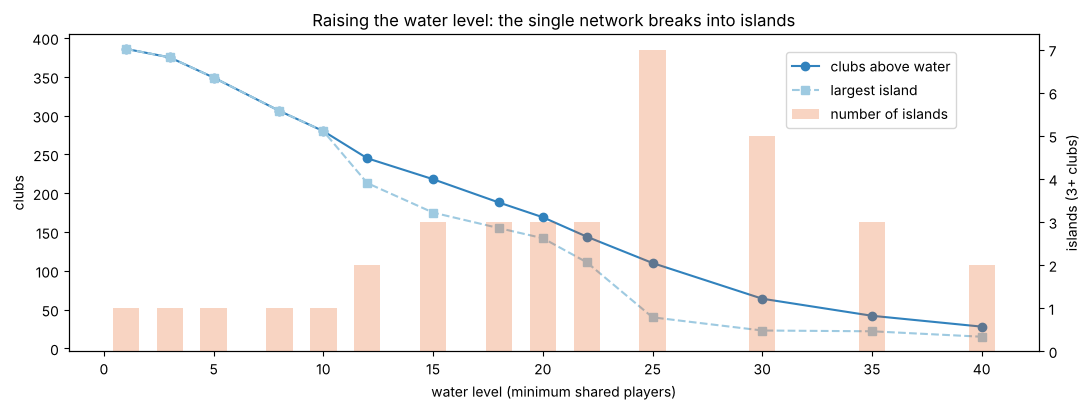

In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 4.2))
ax1.plot(levels_table.iloc[:, 0], levels_table["clubs above water"], "o-", color="#3182bd", label="clubs above water")
ax1.plot(levels_table.iloc[:, 0], [s[0] if s else 0 for s in levels_table["island sizes"]], "s--",
         color="#9ecae1", label="largest island")
ax1.set_xlabel("water level (minimum shared players)"); ax1.set_ylabel("clubs")
ax2 = ax1.twinx()
ax2.bar(levels_table.iloc[:, 0], levels_table["islands (3+ clubs)"], alpha=0.25, color="#e6550d", width=1.2,
        label="number of islands")
ax2.set_ylabel("islands (3+ clubs)")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.title("Raising the water level: the single network breaks into islands")
plt.tight_layout(); plt.show()

### 5a. The order in which the islands appear
Following one island as the water rises shows which leagues are the most internally connected. Russia separates first, then Germany, and by level 25 Europe has broken into national islands.

In [ ]:
first_split = {}
for t, g in island_method(C, range(1, 46)):
    for c in islands(g):
        mix = COUNTRY[list(c)].value_counts()
        if mix.iloc[0] / len(c) >= 0.9:          # an island that is (almost) all one country
            first_split.setdefault(mix.index[0], (t, len(c)))
pd.DataFrame(first_split, index=["first water level as its own island", "clubs in it"]).T \
  .sort_values("first water level as its own island")

,first water level as its own island,clubs in it
Russia,11,33
Germany,13,20
France,21,16
England,23,27
Portugal,23,19
Spain,23,8
Italy,26,25
Netherlands,26,14


### 5b. The islands at water level 25
I pick **water level 25** (clubs that shared at least 25 players) for a closer look, because it is the level where the national groups have separated but most leagues still have an island. Each island is a group of clubs that exchanged players very heavily over 30 years.

In [ ]:
WATER = 25
C25 = trim_edges(C, WATER)
isl25 = islands(C25)
island_of = {club: i + 1 for i, c in enumerate(isl25) for club in c}

summary = []
for i, c in enumerate(isl25, 1):
    sub = C25.subgraph(c)
    strength = dict(sub.degree(weight="weight"))
    summary.append({"island": i, "clubs": len(c), "countries": country_mix(c),
                    "most connected clubs": ", ".join(sorted(strength, key=strength.get, reverse=True)[:5]),
                    "strongest tie": max(((u, v, e["weight"]) for u, v, e in sub.edges(data=True)), key=lambda x: x[2])})
pd.DataFrame(summary).set_index("island")

,clubs,countries,most connected clubs,strongest tie
island,,,,
1,40,"Italy 23, Netherlands 14, England 2, Spain 1","Parma, UC Sampdoria, ACF Fiorentina, Bologna FC 1909, Torino FC","(Parma, Inter Milan, 62)"
2,18,Portugal 18,"SC Braga, Vitória Setúbal FC, FC Porto, SL Benfica, CF Os Belenenses","(FC Porto, SC Braga, 55)"
3,11,England 11,"Leeds United, Derby County, Leicester City, Middlesbrough FC, Crystal Palace","(Leicester City, Derby County, 32)"
4,10,France 10,"Olympique Marseille, AS Monaco, Stade Rennais FC, Olympique Lyon, Paris Saint-Germain","(AS Monaco, Olympique Marseille, 36)"
5,9,Russia 9,"FK Rostov, Krylya Sovetov Samara, Dynamo Moscow, Spartak Moscow, Lokomotiv Moscow","(FK Rostov, Rubin Kazan, 37)"
6,5,Spain 5,"Atlético de Madrid, RCD Mallorca, Getafe CF, RCD Espanyol Barcelona, Sevilla FC","(Atlético de Madrid, RCD Mallorca, 31)"
7,3,Russia 3,"CSKA Moscow, Torpedo Moscow, FC Moscow","(CSKA Moscow, Torpedo Moscow, 25)"
